**Logistic Regression for Diabetes Readmission Prediction**

In this notebook, I worked on predicting whether a patient would be readmitted within 30 days using Logistic Regression. I used the processed data from our group project, compared a regular model with a balanced model, and checked their results on validation and test data.

Checking the saved data
First, I loaded the processed data file prepared for the project. This lets me use the same training and testing data as the rest of the group.

In [20]:

import joblib
import os

file_path = "../data/processed/model_data.joblib"

if not os.path.exists(file_path):
    file_path = "/content/model_data.joblib"

data = joblib.load(file_path)

print("Dataset loaded successfully!")
print("File used:", file_path)
print("Available keys:", list(data.keys()))


Dataset loaded successfully!
File used: ../data/processed/model_data.joblib
Available keys: ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test', 'encoder', 'scaler']


I checked what was saved in the file so I know which parts I can use.

In [21]:

print(type(data))

if isinstance(data, dict):
    for key in data:
        print(key, type(data[key]))


<class 'dict'>
X_train <class 'scipy.sparse._csr.csr_matrix'>
X_val <class 'scipy.sparse._csr.csr_matrix'>
X_test <class 'scipy.sparse._csr.csr_matrix'>
y_train <class 'pandas.core.series.Series'>
y_val <class 'pandas.core.series.Series'>
y_test <class 'pandas.core.series.Series'>
encoder <class 'sklearn.preprocessing._encoders.OneHotEncoder'>
scaler <class 'sklearn.preprocessing._data.StandardScaler'>


In [22]:

y_train = data['y_train']

print("Number of patients in each class:")
print(y_train.value_counts())

print("\nPercentage of each class:")
print(y_train.value_counts(normalize=True) * 100)


Number of patients in each class:
readmitted_30
0    63499
1     8021
Name: count, dtype: int64

Percentage of each class:
readmitted_30
0    88.784955
1    11.215045
Name: proportion, dtype: float64


Checking the training features

In [23]:

X_train = data['X_train']
encoder = data['encoder']

print("Training data shape:", X_train.shape)

print("\nOriginal columns used by encoder:")
print(encoder.feature_names_in_)


Training data shape: (71520, 2376)

Original columns used by encoder:
['race' 'gender' 'age' 'payer_code' 'medical_specialty' 'diag_1' 'diag_2'
 'diag_3' 'max_glu_serum' 'A1Cresult' 'metformin' 'repaglinide'
 'nateglinide' 'chlorpropamide' 'glimepiride' 'acetohexamide' 'glipizide'
 'glyburide' 'tolbutamide' 'pioglitazone' 'rosiglitazone' 'acarbose'
 'miglitol' 'troglitazone' 'tolazamide' 'examide' 'citoglipton' 'insulin'
 'glyburide-metformin' 'glipizide-metformin' 'glimepiride-pioglitazone'
 'metformin-rosiglitazone' 'metformin-pioglitazone' 'change' 'diabetesMed'
 'admission_type_id' 'discharge_disposition_id' 'admission_source_id']


In [24]:

print("Number of columns before encoding:", len(encoder.feature_names_in_))

print("\nColumns with ID in their names:")
for col in encoder.feature_names_in_:
    if "id" in col.lower():
        print(col)

print("\nNumber of features after encoding:", X_train.shape[1])


Number of columns before encoding: 38

Columns with ID in their names:
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
tolazamide
examide
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
admission_type_id
discharge_disposition_id
admission_source_id

Number of features after encoding: 2376


Preparing the data splits

I assigned the training, validation, and test sets to separate variables and checked their sizes before building the model.

In [25]:

X_train = data['X_train']
X_val = data['X_val']
X_test = data['X_test']

y_train = data['y_train']
y_val = data['y_val']
y_test = data['y_test']

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (71520, 2376) (71520,)
Validation: (15027, 2376) (15027,)
Testing: (15219, 2376) (15219,)


Training the regular model

I started with a regular Logistic Regression model to get a baseline result for comparison.

In [26]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


C:\Users\suyog\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


I checked accuracy, precision, recall, and F1 score on the validation set. I wanted to see more than just the overall accuracy.

In [27]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = lr_model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, y_pred, zero_division=0), 4))



Accuracy: 0.8899
Precision: 0.5156
Recall: 0.0199
F1 Score: 0.0384


Confusion matrix for the regular model

[[13340    31]
 [ 1623    33]]


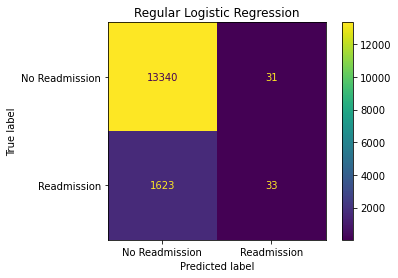

In [28]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmission", "Readmission"]
).plot()

plt.title("Regular Logistic Regression")
plt.show()


Training a balanced model

Since the two classes are not equally represented, I also trained Logistic Regression with balanced class weights to give more attention to the smaller class.

In [29]:

balanced_lr = LogisticRegression(max_iter=1000, class_weight='balanced')

balanced_lr.fit(X_train, y_train)

print("Balanced Logistic Regression training completed!")


Balanced Logistic Regression training completed!


I checked the same validation metrics for the balanced model so I could compare it fairly with the regular one.

In [30]:

balanced_pred = balanced_lr.predict(X_val)

print("Balanced Logistic Regression Results")

print("Accuracy:", round(accuracy_score(y_val, balanced_pred), 4))
print("Precision:", round(precision_score(y_val, balanced_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, balanced_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, balanced_pred, zero_division=0), 4))


Balanced Logistic Regression Results
Accuracy: 0.6532
Precision: 0.1689
Recall: 0.5477
F1 Score: 0.2582


Here, I looked at the balanced model’s mistakes and whether it catches more actual readmission cases.

[[8908 4463]
 [ 749  907]]


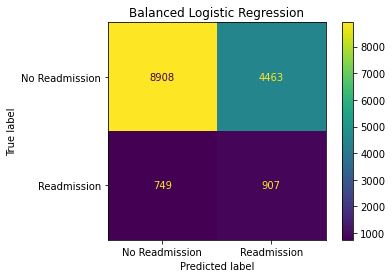

In [31]:

cm_balanced = confusion_matrix(y_val, balanced_pred)

print(cm_balanced)

ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["No Readmission", "Readmission"]
).plot()

plt.title("Balanced Logistic Regression")
plt.show()


Comparing ROC-AUC and PR-AUC

I compared the probability-based scores for both models. PR-AUC is especially useful here because readmission cases are less common.

In [32]:

from sklearn.metrics import roc_auc_score, average_precision_score

regular_prob = lr_model.predict_proba(X_val)[:, 1]
balanced_prob = balanced_lr.predict_proba(X_val)[:, 1]

print("Regular Logistic Regression")
print("ROC-AUC:", round(roc_auc_score(y_val, regular_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, regular_prob), 4))

print("\nBalanced Logistic Regression")
print("ROC-AUC:", round(roc_auc_score(y_val, balanced_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, balanced_prob), 4))


Regular Logistic Regression
ROC-AUC: 0.6497
PR-AUC: 0.2023

Balanced Logistic Regression
ROC-AUC: 0.6488
PR-AUC: 0.1997


I plotted the ROC curves to compare how the models separate the two classes at different thresholds.

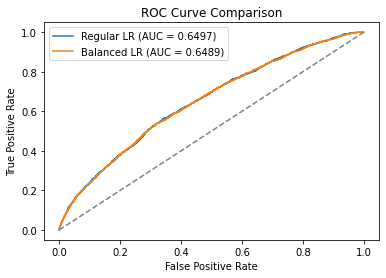

In [33]:

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr1, tpr1, _ = roc_curve(y_val, regular_prob)
fpr2, tpr2, _ = roc_curve(y_val, balanced_prob)

plt.plot(fpr1, tpr1, label="Regular LR (AUC = 0.6497)")
plt.plot(fpr2, tpr2, label="Balanced LR (AUC = 0.6489)")

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


These curves help me see the tradeoff between finding more readmission cases and making more false predictions.

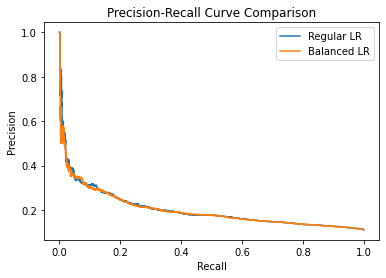

In [34]:

from sklearn.metrics import precision_recall_curve

p1, r1, _ = precision_recall_curve(y_val, regular_prob)
p2, r2, _ = precision_recall_curve(y_val, balanced_prob)

plt.plot(r1, p1, label="Regular LR")
plt.plot(r2, p2, label="Balanced LR")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()


Looking at the original dataset

I loaded the raw hospital dataset to check some basic details separately from the processed model data.

In [37]:

import pandas as pd

csv_path = "../data/diabetic_data.csv"

if not os.path.exists(csv_path):
    csv_path = "/content/diabetic_data.csv"

df = pd.read_csv(csv_path)

print("Total hospital encounters:", len(df))
print("Unique patients:", df['patient_nbr'].nunique())

visits = df['patient_nbr'].value_counts()

print("Patients with multiple encounters:", (visits > 1).sum())
print("Maximum encounters for one patient:", visits.max())


Total hospital encounters: 101766
Unique patients: 71518
Patients with multiple encounters: 16773
Maximum encounters for one patient: 40


Here, I checked whether encounter IDs repeat and how many patient IDs appear more than once. This helps me understand the structure of the original data.

In [38]:

print("Total encounters:", len(df))
print("Unique encounter IDs:", df['encounter_id'].nunique())

print("Duplicate encounter IDs:", df['encounter_id'].duplicated().sum())
print("Duplicate patient IDs:", df['patient_nbr'].duplicated().sum())


Total encounters: 101766
Unique encounter IDs: 101766
Duplicate encounter IDs: 0
Duplicate patient IDs: 30248


After comparing the models on validation data, I evaluated them on the held-out test set to see how they perform on unseen examples.

In [39]:

test_pred = lr_model.predict(X_test)
balanced_test_pred = balanced_lr.predict(X_test)

print("Regular Logistic Regression - Test Results")
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, test_pred, zero_division=0), 4))

print("\nBalanced Logistic Regression - Test Results")
print("Accuracy:", round(accuracy_score(y_test, balanced_test_pred), 4))
print("Precision:", round(precision_score(y_test, balanced_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, balanced_test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, balanced_test_pred, zero_division=0), 4))



Regular Logistic Regression - Test Results
Accuracy: 0.8895
Precision: 0.4928
Recall: 0.0202
F1 Score: 0.0389

Balanced Logistic Regression - Test Results
Accuracy: 0.6636
Precision: 0.1737
Recall: 0.5452
F1 Score: 0.2635


Test ROC-AUC and PR-AUC

I also checked the probability-based scores on the test set rather than relying only on predicted class labels.

In [40]:

regular_test_prob = lr_model.predict_proba(X_test)[:, 1]
balanced_test_prob = balanced_lr.predict_proba(X_test)[:, 1]

print("Regular Logistic Regression")
print("ROC-AUC:", round(roc_auc_score(y_test, regular_test_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, regular_test_prob), 4))

print("\nBalanced Logistic Regression")
print("ROC-AUC:", round(roc_auc_score(y_test, balanced_test_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, balanced_test_prob), 4))


Regular Logistic Regression
ROC-AUC: 0.6639
PR-AUC: 0.2262

Balanced Logistic Regression
ROC-AUC: 0.6597
PR-AUC: 0.2228


Final results comparison

I put the main test metrics into one table so the differences between the regular and balanced models are easier to see.

In [41]:

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"],
    "Regular LR": [
        accuracy_score(y_test, test_pred),
        precision_score(y_test, test_pred, zero_division=0),
        recall_score(y_test, test_pred, zero_division=0),
        f1_score(y_test, test_pred, zero_division=0),
        roc_auc_score(y_test, regular_test_prob),
        average_precision_score(y_test, regular_test_prob)
    ],
    "Balanced LR": [
        accuracy_score(y_test, balanced_test_pred),
        precision_score(y_test, balanced_test_pred, zero_division=0),
        recall_score(y_test, balanced_test_pred, zero_division=0),
        f1_score(y_test, balanced_test_pred, zero_division=0),
        roc_auc_score(y_test, balanced_test_prob),
        average_precision_score(y_test, balanced_test_prob)
    ]
})

print(results.round(4).to_string(index=False))


   Metric  Regular LR  Balanced LR
 Accuracy      0.8895       0.6636
Precision      0.4928       0.1737
   Recall      0.0202       0.5452
 F1 Score      0.0389       0.2635
  ROC-AUC      0.6639       0.6597
   PR-AUC      0.2262       0.2228


In [42]:

cm1 = confusion_matrix(y_test, test_pred)
cm2 = confusion_matrix(y_test, balanced_test_pred)

print("Regular Logistic Regression:")
print(cm1)

print("\nBalanced Logistic Regression:")
print(cm2)


Regular Logistic Regression:
[[13504    35]
 [ 1646    34]]

Balanced Logistic Regression:
[[9183 4356]
 [ 764  916]]


Conclusion
In this notebook, I compared regular and balanced Logistic Regression for predicting 30-day hospital readmission. I used several evaluation metrics and confusion matrices because accuracy alone does not show how well the models identify the smaller readmission class. The final comparison table above helps show the tradeoff between the two approaches. I would choose a model based on the project goal, especially whether finding more readmission cases is more important than avoiding false alarms.

In [43]:
import joblib
import os

In [44]:
os.makedirs("../models",exist_ok=True)
joblib.dump(balanced_lr,"../models/logistic_regression.joblib")
print("Logisitc regression model saved!")

Logisitc regression model saved!
